In [1]:
import xmlrpc.client
import pickle
import pandas as pd

server = xmlrpc.client.ServerProxy("http://127.0.0.1:8008")
stats  = xmlrpc.client.ServerProxy("http://127.0.0.1:8018")

print('Ping:', server.ping())

print('Server datetime:', server.now())

print('View, type, value:', server.type(2))
print('View, type, value:', server.type(2.))
print('View, type, value:', server.type('My string'))
print('View, type, value:', server.type("My string"))
print('View, type, value:', server.type([1,2,3]))
print('View, type, value:', server.type(["one", "two", "three"]))
print('View, type, value:', server.type((1,2,"3")))

print('Sum 2 + 3 :', server.sum(2, 3))
print('Pow 2^3: ', server.pow(2, 3))

Ping: True
Server datetime: 2026-10-01T19:21:25.286811
View, type, value: ['2', "<class 'int'>", 2]
View, type, value: ['2.0', "<class 'float'>", 2.0]
View, type, value: ['My string', "<class 'str'>", 'My string']
View, type, value: ['My string', "<class 'str'>", 'My string']
View, type, value: ['[1, 2, 3]', "<class 'list'>", [1, 2, 3]]
View, type, value: ["['one', 'two', 'three']", "<class 'list'>", ['one', 'two', 'three']]
View, type, value: ["[1, 2, '3']", "<class 'list'>", [1, 2, '3']]
Sum 2 + 3 : 5
Pow 2^3:  8


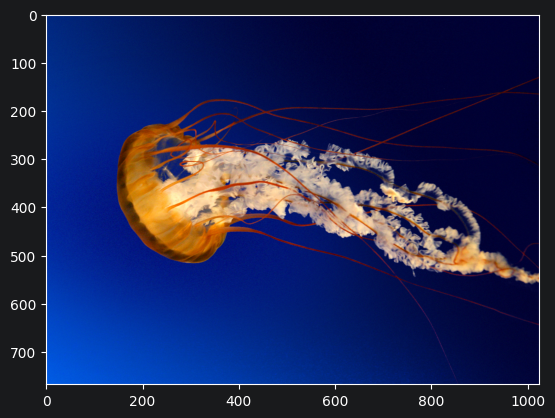

In [2]:
from PIL import Image # Работа с изображением
from pylab import * # Отображение

import xmlrpc.client

# Режим отображения внутри ноутбука
%matplotlib inline

img = Image.open('Jellyfish.jpg')
img_arr = array(img)

# Исходное изображение
imshow(img_arr)

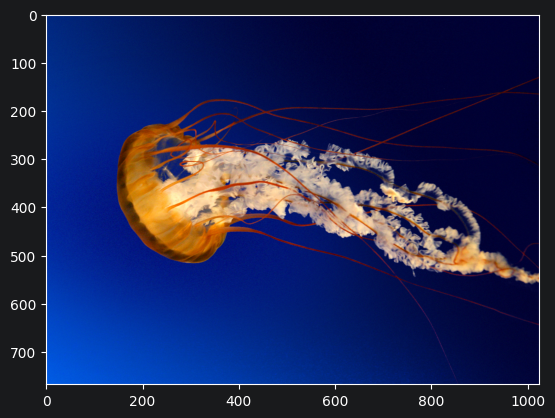

In [3]:
# Тест бинарной передачи данных
#pimg = img_arr.dumps()
pimg = pickle.dumps(img_arr)

img_bin = xmlrpc.client.Binary(pimg)

img_bin2 = server.send_back_binary(img_bin)

#img_arr2 = np.loads(img_bin2.data)
img_arr2 = pickle.loads(img_bin2.data)

# Изображение после возрата с сервера
imshow(img_arr2)

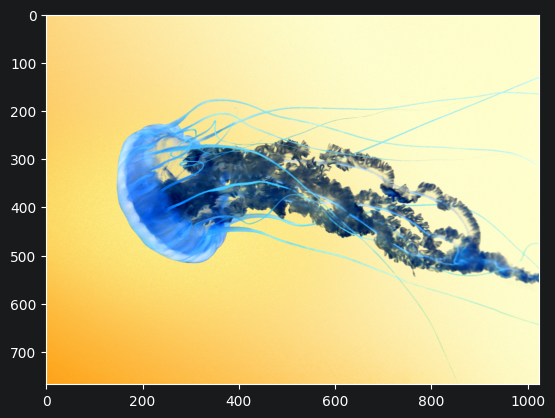

In [4]:
# Инверсия цвета изображения через сервер
def inv_color(img_arr_in):
    pimg = pickle.dumps(img_arr_in)
    img_bin = xmlrpc.client.Binary(pimg)

    img_bin2 = server.color_inversion(img_bin)

    img_arr_out = pickle.loads(img_bin2.data)
    return img_arr_out

img_arr_inv = inv_color(img_arr)

# Изображение с инверсией цвета
imshow(img_arr_inv)

In [5]:

# Проверка черного списка по фамилии
for s in ['Петров', 'петров', 'ПЕТРОВ', 'Петро', 'Примеров', 'Свeтлый']:
    print(server.black_list_check(s))

['Петров: yes', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['петров: yes', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['ПЕТРОВ: yes', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['Петро: similar', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['Примеров: no']
['Свeтлый: similar', [{'Surname': 'Светлый', 'Name': 'Михаил', 'Patronym': 'Викторович', 'Birth': '13.02.1992', 'City': 'Рязань', 'Position': 'менеджер'}]]


In [7]:
# Проверка черного списка по ФИО и дате
print(server.black_list_check_fio('Петров', 'Пётр ', 'Петрович', '07.08.1985'))
print(server.black_list_check_fio('петров', 'петр', 'петрович', '07.08.1985'))
print(server.black_list_check_fio('Петро',  'Петр', 'Петрович', '07.08.1985'))
print(server.black_list_check_fio('Примеров', 'Петр', 'Петрович', '20.03.1985'))

['Петров Пётр  Петрович, 07.08.1985: similar', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['петров петр петрович, 07.08.1985: yes', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['Петро Петр Петрович, 07.08.1985: similar', [{'Surname': 'Петров', 'Name': 'Петр', 'Patronym': 'Петрович', 'Birth': '07.08.1985', 'City': 'Москва', 'Position': 'инженер'}]]
['Примеров Петр Петрович, 20.03.1985: no']


3
Порог =  64  |  процент пикселей > порога: 26.80%


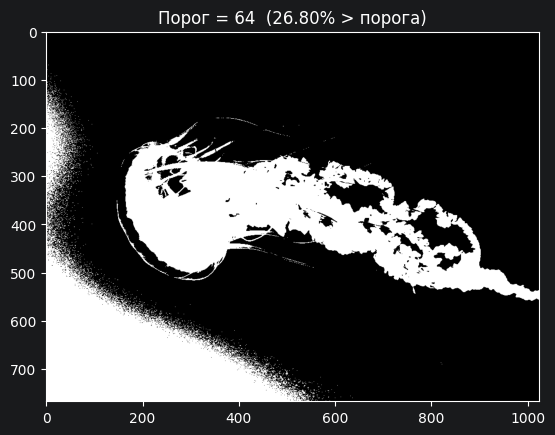

3
Порог = 128  |  процент пикселей > порога: 8.92%


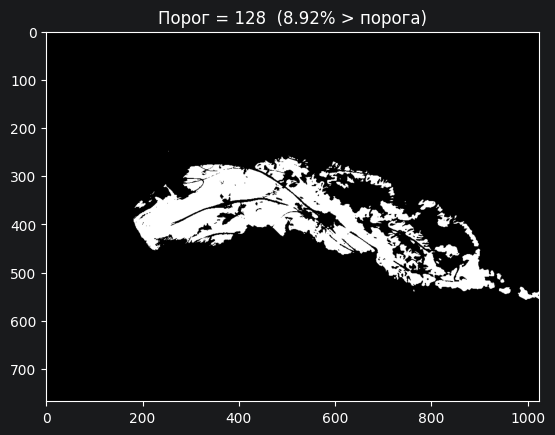

3
Порог = 192  |  процент пикселей > порога: 1.91%


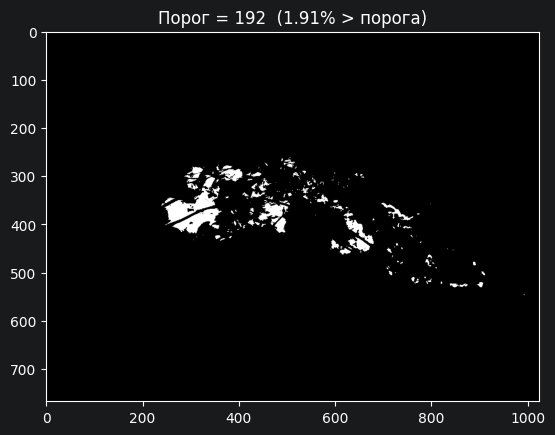

In [8]:
# Бинаризация изображения по порогу
def binarize_image_percent(img_arr_in, threshold):
    pimg = pickle.dumps(img_arr_in)
    img_bin = xmlrpc.client.Binary(pimg)
    print(img_arr.ndim)
    img_bin2, percent = server.binarization_percent(img_bin, threshold)
    return pickle.loads(img_bin2.data), percent

for thr in [64, 128, 192]:
    img_arr_bin, percent = binarize_image_percent(img_arr, thr)
    print(f'Порог = {thr:3d}  |  процент пикселей > порога: {percent:.2f}%')
    figure()
    imshow(img_arr_bin, cmap='gray')
    title(f'Порог = {thr}  ({percent:.2f}% > порога)')
    show()

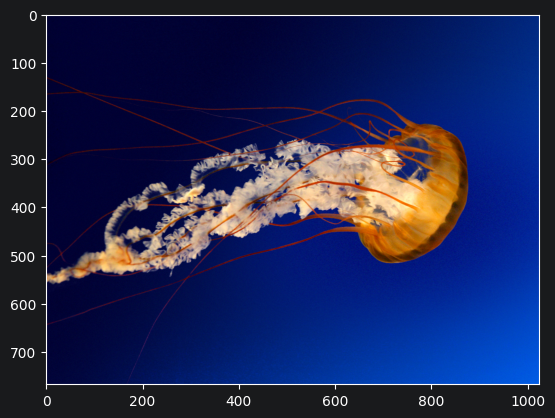

In [9]:
# Разворот изображения относительно вертикали
def flip_vertical_image(img_arr_in):
    pimg = pickle.dumps(img_arr_in)
    img_bin = xmlrpc.client.Binary(pimg)
    img_bin2 = server.flip_vertical(img_bin)
    img_arr_out = pickle.loads(img_bin2.data)
    return img_arr_out

img_arr_flipped = flip_vertical_image(img_arr)

# Развёрнутое изображение
imshow(img_arr_flipped)

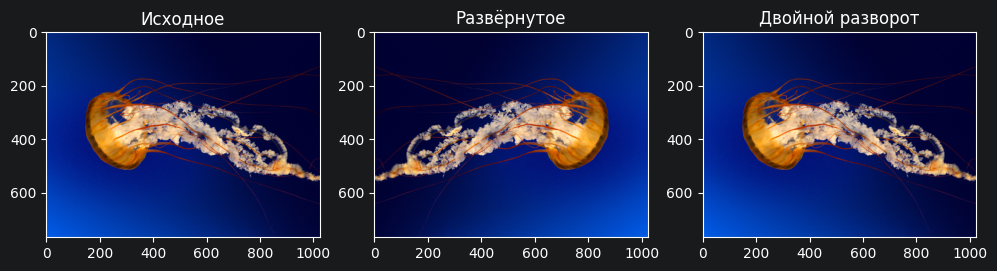

Двойной разворот совпадает с исходным: True


In [10]:

# Проверка корректности разворота: двойной разворот должен вернуть исходное
img_arr_double_flipped = flip_vertical_image(img_arr_flipped)

figure(figsize=(12, 4))
subplot(1, 3, 1)
imshow(img_arr)
title('Исходное')

subplot(1, 3, 2)
imshow(img_arr_flipped)
title('Развёрнутое')

subplot(1, 3, 3)
imshow(img_arr_double_flipped)
title('Двойной разворот')
show()

# Проверка равенства массивов
import numpy as np
print('Двойной разворот совпадает с исходным:',
      np.array_equal(img_arr, img_arr_double_flipped))

In [21]:
# Получение журнала событий сервиса статистики
print("Все события:")
events = stats.get_events()
for e in events:
    print(e)

print("\nТолько события binarization_percent:")
events_bp = stats.get_events('black_list_check_fio')
for e in events_bp:
    print(e)

print("\nСрез по времени (с 2026-10-06 19:00:00 до 2026-10-01 19:05:00):")
events_dt = stats.get_events('black_list_check_fio',
                             '2026-10-01 19:20:00',
                             '2026-10-01 19:25:00')
for e in events_dt:
    print(e)

print("\nТипы событий в журнале:", stats.get_event_types())
print("Размер журнала (записей):", stats.get_log_size())


Все события:
{'event_type': 'sum', 'details': '2+3', 'timestamp': '2026-10-01 19:02:13'}
{'event_type': 'pow', 'details': '2^3', 'timestamp': '2026-10-01 19:02:13'}
{'event_type': 'send_back_binary', 'details': '', 'timestamp': '2026-10-01 19:02:18'}
{'event_type': 'color_inversion', 'details': '', 'timestamp': '2026-10-01 19:02:21'}
{'event_type': 'binarization_percent', 'details': 'threshold=64', 'timestamp': '2026-10-01 19:02:27'}
{'event_type': 'binarization_percent', 'details': 'threshold=128', 'timestamp': '2026-10-01 19:02:30'}
{'event_type': 'binarization_percent', 'details': 'threshold=192', 'timestamp': '2026-10-01 19:02:32'}
{'event_type': 'binarization_percent', 'details': 'threshold=64', 'timestamp': '2026-10-01 19:04:59'}
{'event_type': 'binarization_percent', 'details': 'threshold=128', 'timestamp': '2026-10-01 19:05:02'}
{'event_type': 'binarization_percent', 'details': 'threshold=192', 'timestamp': '2026-10-01 19:05:04'}
{'event_type': 'flip_vertical', 'details': '', '